# Can a portfolio follow the stock purchases of members of the US Congress?

**Advanced applied statistical modeling — project.** Topic: convex relaxation (ℓ1 for sparse selection, nuclear norm + ℓ1 for Robust PCA).

**Role taken:** consultant for a client who wants an automated portfolio that buys what members of Congress buy, restricted to the stocks allowed by the client's investment mandate.

**How to read this notebook.** Section 0 is the one-page answer. Sections 1 to 7 justify it. Every number is computed by the code of the repository (`csig/`, `scripts/`) from public data; this notebook reads the stored tables and results, so it runs in about a minute without any download. The commands that rebuild everything are in the appendix.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

from csig.config import load_config
from csig.data.trades import signals
from csig.models import rpca

cfg = load_config()
store, results = ROOT / "data" / "store", ROOT / "results"
trades = pd.read_parquet(store / "trades.parquet")            # every disclosed transaction read from the filings
st = signals(trades, cfg)                                      # stock purchases and sales with usable dates and tickers
log = pd.read_parquet(store / "ingest_log.parquet")            # one row per filing: read, or not readable
res = json.loads((results / "research.json").read_text())      # walk-forward experiment, development period
det = json.loads((results / "detectability.json").read_text()) # simulation study of section 3
growth = pd.read_parquet(results / "growth.parquet")           # growth of 1 for each rule and for the S&P 500
lock = pd.Timestamp(res["locked_from"])
dev = st[st["disclosure_date"] < lock]                         # the last two years are not looked at (section 1)
buys = dev[dev["side"] == "buy"]
pct = lambda x, d=1: f"{100 * x:+.{d}f}%"

## 0. Summary

In [2]:
P, M_ = res["portfolios"], res["models"]
spy = growth["SPY"]; years = (growth.index[-1] - growth.index[0]).days / 365.25
spy_cagr = spy.iloc[-1] ** (1 / years) - 1
every, most, most_s = P["copy_everything|unscreened"], P["most_bought|unscreened"], P["most_bought|screened"]
real = det["real_structure_recovery_by_edge"]
display(Markdown(f'''
**Question.** Members of Congress must disclose their stock trades within 45 days. Can a rule that buys what they
buy, after the disclosure, beat the market, and can sparse methods find *which* members or trades to follow?

**Data.** {len(log):,} trade filings from the two official sites, 2014 to 2026; {int((log.status == "parsed").sum()):,} are electronic and were read,
the others are scans of paper forms. Development period: {res["from"]} to {res["to"]}; rules are judged from {res["judged_from"]}.
{res["events"]:,} disclosed purchases with prices, by {res["members"]} members. The last 24 months are locked and have not been looked at.

**Methods.** (1) LASSO, the ℓ1 relaxation of best-subset selection, on purchase features and one indicator per member, refitted
walk-forward; OMP, ridge, least squares, boosted trees and "follow past winners" as comparators. (2) Robust PCA
(nuclear norm + ℓ1) on the members × stocks matrix, to separate purchases explained by common behaviour from unusual ones.
(3) A simulation on the real trade structure, to know beforehand what size of effect could be detected at all.

**Answer.**
- The average disclosed purchase does not beat the market: {pct(res["outcome_mean_all_purchases"], 2)} against the S&P 500 over the next 63 trading days (standard deviation {100 * res["outcome_sd"]:.1f}%).
- Holding every recently disclosed purchase returns {pct(every["cagr"])} a year against {pct(spy_cagr)} for the S&P 500. Holding the 15 most bought stocks returns {pct(most["cagr"])}; restricted to the client's mandate, {pct(most_s["cagr"])}.
- The LASSO selects **nothing** in {M_["lasso"]["months_without_ranking"]} of {M_["lasso"]["months"]} months. When it selects something, its ranking is not better than chance (monthly rank correlation {M_["lasso"]["monthly_ic_mean"]:+.3f}, t = {M_["lasso"]["monthly_ic_t"]:+.1f}). No comparator does better.
- This is what the simulation predicts: with the real number of purchases per member (median {det["median_purchases_per_member"]:.0f}), three members earning 10% more than the market on *every* purchase would be identified only {100 * real["0.1"]:.0f}% of the time, and with no skill at all the five best members still look {pct(det["leaderboard_illusion"]["apparent_edge_of_top_mean"])} better per purchase by luck.
- Purchases that Robust PCA flags as unusual do slightly *worse* than the others (t = {M_["rpca_unusual"]["monthly_spread_t"]:+.1f}), the opposite of the "informed trade" idea.
- No rule beats random portfolios of eligible stocks of the same size.

**Recommendation to the client.** Do not put money on this rule. The honest statement is not "members have no information" but
"with the delay, the noise and the number of trades available, public disclosures do not allow anyone to tell, and the rules tested lose to the index".

**Main limits.** Paper filings are missing ({100 * (log.status.isin(["scan", "paper"])).mean():.0f}% of filings); amounts are ranges; delisted companies have prices from 2016 only;
the mandate's activity filter relies on coarse sector codes. Details in section 7.
'''))


**Question.** Members of Congress must disclose their stock trades within 45 days. Can a rule that buys what they
buy, after the disclosure, beat the market, and can sparse methods find *which* members or trades to follow?

**Data.** 10,898 trade filings from the two official sites, 2014 to 2026; 7,835 are electronic and were read,
the others are scans of paper forms. Development period: 2014-01-06 to 2024-11-08; rules are judged from 2016-01-04.
18,986 disclosed purchases with prices, by 196 members. The last 24 months are locked and have not been looked at.

**Methods.** (1) LASSO, the ℓ1 relaxation of best-subset selection, on purchase features and one indicator per member, refitted
walk-forward; OMP, ridge, least squares, boosted trees and "follow past winners" as comparators. (2) Robust PCA
(nuclear norm + ℓ1) on the members × stocks matrix, to separate purchases explained by common behaviour from unusual ones.
(3) A simulation on the real trade structure, to know beforehand what size of effect could be detected at all.

**Answer.**
- The average disclosed purchase does not beat the market: -0.33% against the S&P 500 over the next 63 trading days (standard deviation 14.5%).
- Holding every recently disclosed purchase returns +10.7% a year against +15.2% for the S&P 500. Holding the 15 most bought stocks returns +15.2%; restricted to the client's mandate, +9.3%.
- The LASSO selects **nothing** in 63 of 104 months. When it selects something, its ranking is not better than chance (monthly rank correlation -0.017, t = -0.8). No comparator does better.
- This is what the simulation predicts: with the real number of purchases per member (median 25), three members earning 10% more than the market on *every* purchase would be identified only 40% of the time, and with no skill at all the five best members still look +8.3% better per purchase by luck.
- Purchases that Robust PCA flags as unusual do slightly *worse* than the others (t = -2.4), the opposite of the "informed trade" idea.
- No rule beats random portfolios of eligible stocks of the same size.

**Recommendation to the client.** Do not put money on this rule. The honest statement is not "members have no information" but
"with the delay, the noise and the number of trades available, public disclosures do not allow anyone to tell, and the rules tested lose to the index".

**Main limits.** Paper filings are missing (28% of filings); amounts are ranges; delisted companies have prices from 2016 only;
the mandate's activity filter relies on coarse sector codes. Details in section 7.


## 1. The question, and the rules fixed before looking at any result

A backtest can always be made to look good by trying many variants. Four rules were therefore fixed first.

1. **Timing as an investor lives it.** A trade made on day *d* is disclosed up to 45 days later. The rule can act only on the first trading day **after the disclosure date** $t_0$. The outcome of purchase $i$ is the abnormal return over $H = 63$ trading days: $y_i = \frac{P_{t_0+H}}{P_{t_0}} - \frac{\text{SPY}_{t_0+H}}{\text{SPY}_{t_0}}$.
2. **Walk-forward only.** A model used on day *d* is trained on purchases whose 63-day outcome was already known on day *d*. Company accounts used by the mandate are those *filed* before *d*.
3. **A locked period.** The last 24 months of data are not read by the research code until the method is frozen. They will be opened once, for the final version.
4. **Two benchmarks.** The S&P 500, and random portfolios: each stock held by a rule is replaced by a random eligible stock of similar size, bought the same day, with the same weight, held as long. A rule must beat 95% of them to count as selection skill.

The client's mandate is a private filter: balance-sheet limits and excluded activities. Its rules are not part of this repository; the list of eligible stocks on each date (`data/store/eligibility.parquet`), computed from accounts filed before that date, is an input of the study. It is a constraint of the problem, not something to optimise.

## 2. Data

| Source | What | Link |
|---|---|---|
| Clerk of the House | Periodic Transaction Reports (PDF) | https://disclosures-clerk.house.gov/FinancialDisclosure |
| Senate eFD | Periodic Transaction Reports (HTML) | https://efdsearch.senate.gov/search/ |
| `unitedstates/congress-legislators` | members, parties, terms, committees | https://github.com/unitedstates/congress-legislators |
| Yahoo Finance, Alpaca market data | daily prices (Alpaca for renamed and delisted companies) | https://finance.yahoo.com , https://alpaca.markets/data |
| SEC EDGAR | company accounts as filed, sector codes | https://www.sec.gov/edgar |
| Ken French data library | factor returns | https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html |

The reports are public; federal law (5 U.S.C. § 13107) forbids using them for a commercial purpose. This is a course project.

In [3]:
status = log.assign(kind=log.status.map({"parsed": "electronic, read", "no_rows": "electronic, no transaction",
                                         "scan": "paper (scan), not read", "paper": "paper (scan), not read"}))
display(status.pivot_table(index="source", columns="kind", values="key", aggfunc="count", fill_value=0))
by = lambda d: d.groupby(["chamber", "side"]).size().unstack()
print("Stock trades kept (whole history):"); display(by(st))
c = buys["member_name"].value_counts()
print(f"Development period: {len(buys):,} purchases, {buys.member_name.nunique()} members, {buys.ticker.nunique():,} stocks.")
print(f"Purchases per member: median {c.median():.0f}; {int((c >= 100).sum())} members have 100 or more; "
      f"the 5 most active make {100 * c.head(5).sum() / len(buys):.0f}% of all purchases.")
print(f"Delay between trade and disclosure: median {buys.lag_days.median():.0f} days; {100 * (buys.lag_days > 45).mean():.0f}% later than 45 days.")

kind,"electronic, no transaction","electronic, read","paper (scan), not read"
source,,,
house,0,6007,2454
senate,4,1828,605


Stock trades kept (whole history):


side,buy,sell
chamber,,
house,20218,21692
senate,4453,4681


Development period: 19,386 purchases, 210 members, 2,542 stocks.
Purchases per member: median 25; 50 members have 100 or more; the 5 most active make 24% of all purchases.
Delay between trade and disclosure: median 26 days; 14% later than 45 days.


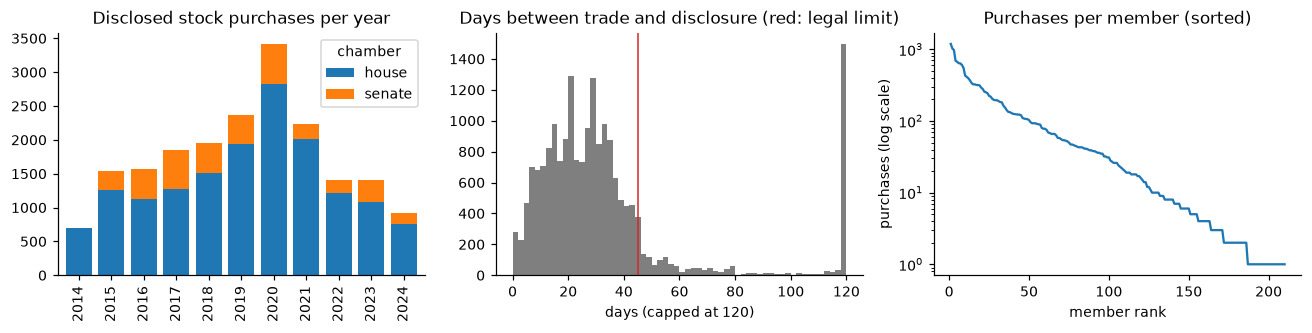

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.1))
buys.groupby([buys.disclosure_date.dt.year, "chamber"]).size().unstack().plot.bar(stacked=True, ax=ax[0], width=0.8)
ax[0].set(title="Disclosed stock purchases per year", xlabel="")
ax[1].hist(buys.lag_days.clip(upper=120), bins=60, color="tab:gray"); ax[1].axvline(45, color="tab:red", lw=1)
ax[1].set(title="Days between trade and disclosure (red: legal limit)", xlabel="days (capped at 120)")
ax[2].plot(np.arange(1, len(c) + 1), c.to_numpy(), color="tab:blue"); ax[2].set_yscale("log")
ax[2].set(title="Purchases per member (sorted)", xlabel="member rank", ylabel="purchases (log scale)")
plt.tight_layout(); plt.show()

**Reading.** The data is small and very uneven: a few members make most trades, and half of the members have fewer than a few dozen purchases in ten years. One purchase is a very noisy observation (standard deviation of $y_i$ around 14.5%). This shapes everything that follows.

**How the tables were built** (`csig/data/`). House filings are PDFs: their text is extracted once and stored, then parsed by rules written against real filings (57,671 of 57,673 transaction lines are recognised). Three properties of the raw material had to be handled: the text layer of many PDFs has broken letter case; the form had no "asset type" box before April 2018 (the type is then read from the wording, and those rows are flagged); the description box tells when a purchase is not a decision (dividend reinvestment, spin-off, inheritance: dropped) and gives the direction of option trades. Options are never traded by the rules: buying a call is read as a purchase signal on the underlying stock.

## 3. From selection to a convex program, and what can be detected

**Model.** $y_i = x_i^\top \beta + \varepsilon_i$, where $x_i$ gathers 22 features of purchase $i$ (delay, price run-up before disclosure, size, owner, number of members buying the same stock in 30 days, party, seniority, leadership, committee matching the stock's sector, home-state company, ...) and **one indicator per member** with at least 8 past purchases.

**Hypothesis.** If a few members are informed, $\beta$ is **sparse** on the member indicators. Selecting them is best-subset selection,
$$\min_\beta \ \tfrac{1}{2n}\lVert y - X\beta\rVert_2^2 \quad \text{s.t.} \quad \lVert\beta\rVert_0 \le s ,$$
which is combinatorial. Its convex relaxation replaces $\lVert\cdot\rVert_0$ by $\lVert\cdot\rVert_1$ (the LASSO):
$$\hat\beta \in \arg\min_\beta \ \tfrac{1}{2n}\lVert y - X\beta\rVert_2^2 + \lambda \lVert\beta\rVert_1 .$$
As in compressed sensing, the relaxation succeeds when the design is well conditioned on sparse vectors **and** the non-zero coefficients stand above the noise level $\lambda \approx \sigma\sqrt{2\log p / n}$.

**Here the design is the easy part.** Each purchase belongs to one member, so the member columns are orthogonal: no incoherence problem. The difficulty is entirely the noise. A member with $n_m$ purchases has an average outcome known up to $\sigma/\sqrt{n_m}$; an edge $\delta$ is detectable among $p$ members roughly when
$$\delta \ \gtrsim\ \sigma\sqrt{\frac{2\log p}{n_m}} .$$

In [5]:
sigma, p, n_m = res["outcome_sd"], det["members"], det["median_purchases_per_member"]
print(f"sigma = {100 * sigma:.1f}%, p = {p} members, median purchases per member = {n_m:.0f}")
print(f"detection threshold for a typical member: {100 * sigma * np.sqrt(2 * np.log(p) / n_m):.1f}% per purchase, every purchase, for ten years")
print(f"for a member with 100 purchases: {100 * sigma * np.sqrt(2 * np.log(p) / 100):.1f}%")

sigma = 14.5%, p = 210 members, median purchases per member = 25
detection threshold for a typical member: 9.5% per purchase, every purchase, for ten years
for a member with 100 purchases: 4.7%


An edge of several percent on **every** trade, net of a delay of several weeks, would be an extraordinary skill. The formula says that for a typical member even that would be at the limit of what can be seen. The simulation below checks it without any approximation: outcomes are simulated (pure noise plus a planted edge for 3 members), the LASSO is fitted, and we count how often its 3 largest coefficients are exactly the 3 informed members. The diagram is the analogue of the phase-transition diagrams of the course: recovery fails below a frontier and succeeds above it.

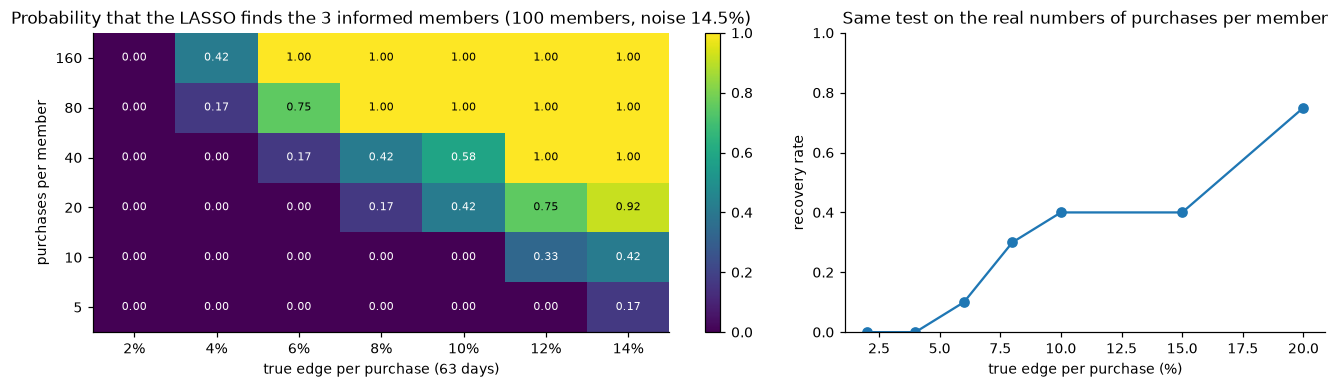

With NO informed member, the 5 best of 155 members look 8.3% better than the market per purchase (90% interval 6.1% to 10.9%).


In [6]:
grid = pd.DataFrame(det["phase_transition"]).T.astype(float)        # rows: purchases per member, columns: edge
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
im = ax[0].imshow(grid.to_numpy(), origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax[0].set_xticks(range(grid.shape[1]), [f"{100 * float(e):.0f}%" for e in grid.columns]); ax[0].set_yticks(range(grid.shape[0]), grid.index)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ax[0].text(j, i, f"{grid.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if grid.iloc[i, j] < 0.6 else "black")
ax[0].set(xlabel="true edge per purchase (63 days)", ylabel="purchases per member",
          title=f"Probability that the LASSO finds the 3 informed members (100 members, noise {100 * det['noise_sd']:.1f}%)")
fig.colorbar(im, ax=ax[0])
r = pd.Series(det["real_structure_recovery_by_edge"]).astype(float)
ax[1].plot([100 * float(e) for e in r.index], r.to_numpy(), marker="o"); ax[1].set_ylim(0, 1)
ax[1].set(xlabel="true edge per purchase (%)", ylabel="recovery rate", title="Same test on the real numbers of purchases per member")
plt.tight_layout(); plt.show()
li = det["leaderboard_illusion"]
print(f"With NO informed member, the 5 best of {li['members_ranked']} members look {100 * li['apparent_edge_of_top_mean']:.1f}% better than the market per purchase "
      f"(90% interval {100 * li['apparent_edge_of_top_5pct_95pct'][0]:.1f}% to {100 * li['apparent_edge_of_top_5pct_95pct'][1]:.1f}%).")

**Reading.** Two conclusions before any real return is used. First, a ranking of members by past performance is worthless at this sample size: pure luck produces "top performers" several percent ahead. Second, if the LASSO finds nothing on the real data, that will not prove that nobody is informed; it will mean that the data cannot tell. A small live example shows the two regimes: with many purchases and a large edge the informed members stand out; with the real counts and a small edge the outcome depends on the draw (an informed member is found only if he happens to trade a lot).

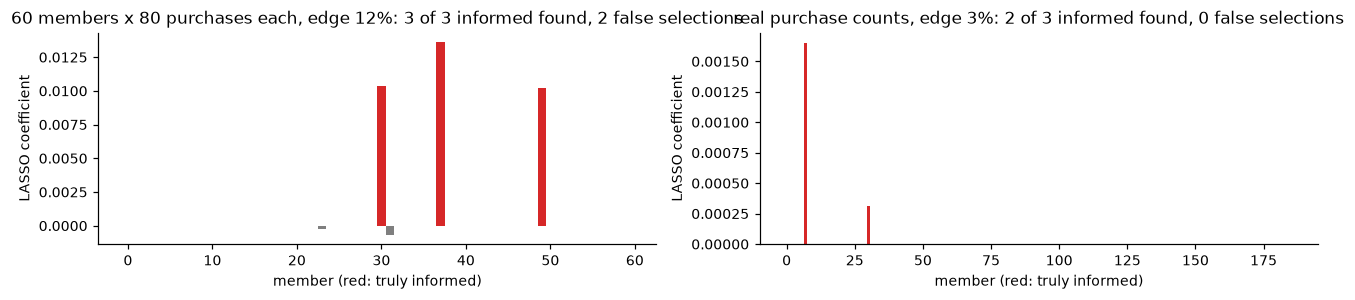

In [7]:
from sklearn.linear_model import LassoCV
from csig.sim import simulate_labels

def lasso_on_members(who, y, p):
    "LASSO on one standardised indicator column per member; the penalty is chosen by 5-fold cross-validation."
    X = np.zeros((len(who), p)); X[np.arange(len(who)), who] = 1.0
    X = (X - X.mean(0)) / np.where(X.std(0) > 0, X.std(0), 1.0)
    order = np.random.default_rng(0).permutation(len(y))
    return LassoCV(cv=5, alphas=30, max_iter=5000).fit(X[order], y[order] - y.mean()).coef_

rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 2.8))
for a, (counts, edge, title) in zip(ax, [(pd.Series(np.full(60, 80)), 0.12, "60 members x 80 purchases each, edge 12%"),
                                          (c[c >= 2].reset_index(drop=True), 0.03, "real purchase counts, edge 3%")]):
    who, y, informed = simulate_labels(counts, 3, edge, res["outcome_sd"], rng)       # 3 informed members, drawn at random
    coef = lasso_on_members(who, y, len(counts))
    found, false = int(((coef > 0) & informed).sum()), int(((coef != 0) & ~informed).sum())
    a.bar(np.arange(len(coef)), coef, color=np.where(informed, "tab:red", "tab:gray"), width=1.0)
    a.set(title=f"{title}: {found} of 3 informed found, {false} false selections", xlabel="member (red: truly informed)", ylabel="LASSO coefficient")
plt.tight_layout(); plt.show()

## 4. Robust PCA: herd purchases and unusual purchases

A second idea: an informed purchase should look **unusual**, not explained by what members commonly buy. Let $M$ be the members × stocks matrix of purchases over one year (log of the dollar amount, 0 when no purchase). We look for
$$M = L + S, \qquad L \text{ low rank (common behaviour: everybody buys Apple and Microsoft)}, \quad S \text{ sparse (purchases specific to one member)}.$$
Minimising $\operatorname{rank}(L) + \lambda\lVert S\rVert_0$ is intractable; Principal Component Pursuit relaxes both terms,
$$\min_{L,S}\ \lVert L\rVert_* + \lambda\lVert S\rVert_1 \quad\text{s.t.}\quad L + S = M ,$$
the nuclear norm being to the rank what $\ell_1$ is to $\ell_0$ (same relaxation as in matrix completion). It is solved by an augmented Lagrangian scheme that alternates singular-value thresholding (for $L$) and entrywise soft thresholding (for $S$): `csig/models/rpca.py`, 25 lines. The score of a purchase is the share of its entry carried by $S$.

M: 32 members x 139 stocks, 473 purchases (10.6% of the entries)
rank of L: 5 (rank of M: 32); share of purchases with a non-zero entry in S: 77%


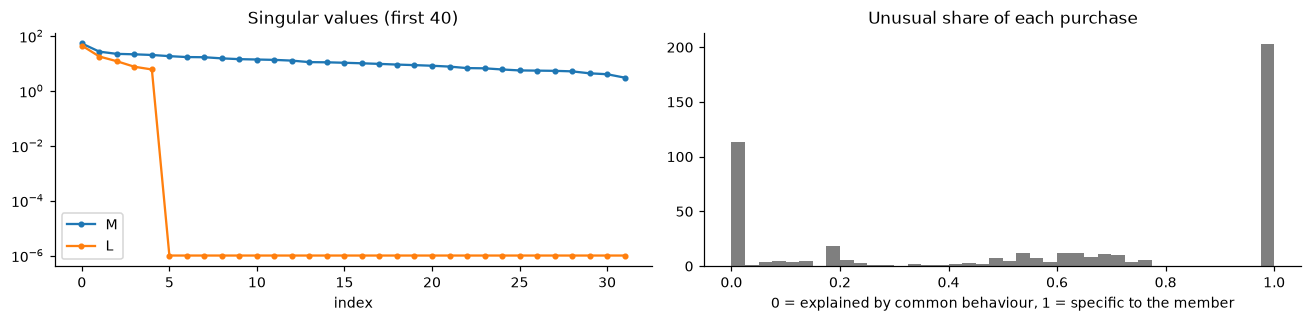

Stocks carried by the common part: MSFT, AAPL, NVDA, BRK.B, GOOG, HD, AMD, AVGO


In [8]:
window = buys[buys.disclosure_date >= buys.disclosure_date.max() - pd.Timedelta(days=365)]     # last year of the development period
Mx = rpca.trade_matrix(window)
fit = rpca.pcp(Mx.to_numpy(), cfg["rpca"]["lam_scale"] / np.sqrt(max(Mx.shape)))
L, S = fit["L"], fit["S"]
nz = Mx.to_numpy() > 0
print(f"M: {Mx.shape[0]} members x {Mx.shape[1]} stocks, {int(nz.sum())} purchases ({100 * nz.mean():.1f}% of the entries)")
print(f"rank of L: {fit['rank']} (rank of M: {np.linalg.matrix_rank(Mx.to_numpy())}); share of purchases with a non-zero entry in S: {100 * (np.abs(S[nz]) > 1e-8).mean():.0f}%")
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].semilogy(np.linalg.svd(Mx.to_numpy(), compute_uv=False)[:40], marker=".", label="M")
ax[0].semilogy(np.linalg.svd(L, compute_uv=False)[:40].clip(1e-6), marker=".", label="L")
ax[0].set(title="Singular values (first 40)", xlabel="index"); ax[0].legend()
share = np.abs(S) / (np.abs(S) + np.abs(L) + 1e-12)
ax[1].hist(share[nz], bins=40, color="tab:gray"); ax[1].set(title="Unusual share of each purchase", xlabel="0 = explained by common behaviour, 1 = specific to the member")
plt.tight_layout(); plt.show()
herd = pd.Series((np.abs(L) * nz).sum(axis=0), index=Mx.columns).nlargest(8).index.tolist()
print("Stocks carried by the common part:", ", ".join(herd))

**Reading.** The low-rank part captures the stocks that many members buy; the sparse part isolates purchases that are specific to one member. Whether the unusual purchases perform better is an empirical question, answered in the next section with the score computed walk-forward (each purchase is scored with the matrix of the year before its disclosure). The parameter $\lambda$ is the theoretical value $1/\sqrt{\max(n_1,n_2)}$ times 1.5, chosen so that the sparse part is not empty or full; it was fixed before looking at returns.

## 5. Walk-forward experiment on real outcomes

Protocol (`scripts/run_research.py`, `csig/models/sparse.py`): every 63 trading days the models are refitted on all purchases whose outcome is already known; the penalty of the LASSO is chosen by time-ordered cross-validation inside the training set; the fitted model scores the purchases disclosed during the next 63 days. Nothing from the future enters a score.

A score is judged **month by month**: inside each month, rank correlation between score and outcome, and difference of mean outcome between the top 20% and the rest; then the average over months and its t-statistic. A pooled evaluation would mix selection skill with the fact that the average level of a forecast moves over time. A month in which a model gives the same score to every purchase (a sparse model that selected nothing) has no ranking.

,months,months with no ranking,monthly rank correlation,t,top 20% minus rest,t,non-zero coefficients (median)
score,,,,,,,
LASSO (l1),104,63,-0.017,-0.8,-0.17%,-0.1,0.0
OMP (greedy l0),104,19,-0.016,-0.9,-0.84%,-1.4,1.0
ridge,104,0,0.000,0.0,-0.41%,-0.8,111.0
least squares,104,0,-0.000,-0.0,-0.25%,-0.5,111.0
boosted trees,104,0,-0.003,-0.2,-0.12%,-0.3,0.0
follow past winners,104,0,-0.007,-0.5,-0.20%,-0.4,
Robust PCA unusual score,104,0,-0.025,-2.1,-1.25%,-2.4,


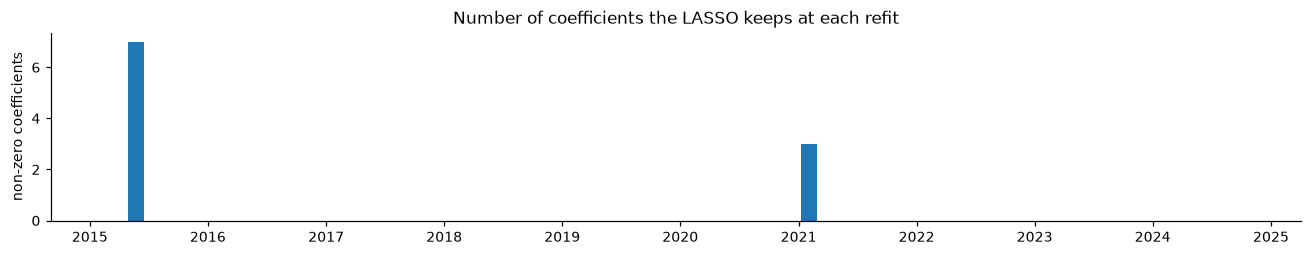

Selected at least once (share of refits): {'consensus_30d': 0.04, 'runup': 0.02, 'committee_match': 0.02, 'home_state': 0.02, 'member::C001123': 0.02, 'member::B001292': 0.02, 'member::M001180': 0.02, 'member::H001061': 0.02, 'member::H000636': 0.02}
All purchases, mean outcome by horizon (trading days): {'21': '-0.06%', '63': '-0.33%', '126': '-0.69%'}
Stocks sold by members, 63 days after the disclosure: -0.46%


In [9]:
names = {"lasso": "LASSO (l1)", "omp": "OMP (greedy l0)", "ridge": "ridge", "ols": "least squares", "gbm": "boosted trees",
         "past_winners": "follow past winners", "rpca_unusual": "Robust PCA unusual score"}
rows = [{"score": names[k], "months": v["months"], "months with no ranking": v["months_without_ranking"],
         "monthly rank correlation": round(v["monthly_ic_mean"], 3), "t": round(v["monthly_ic_t"], 1),
         "top 20% minus rest": pct(v["monthly_spread_mean"], 2), "t ": round(v["monthly_spread_t"], 1),
         "non-zero coefficients (median)": v.get("nonzero_coefficients_median", "")} for k, v in res["models"].items() if k in names]
display(pd.DataFrame(rows).set_index("score"))
nzr = pd.Series(res["lasso_nonzero_by_refit"]); nzr.index = pd.to_datetime(nzr.index)
fig, ax = plt.subplots(figsize=(12, 2.4)); ax.bar(nzr.index, nzr.to_numpy(), width=50, color="tab:blue")
ax.set(title="Number of coefficients the LASSO keeps at each refit", ylabel="non-zero coefficients"); plt.tight_layout(); plt.show()
print("Selected at least once (share of refits):", res["lasso_selection_frequency"])
print(f"All purchases, mean outcome by horizon (trading days): { {h: pct(v, 2) for h, v in res['horizons_mean'].items()} }")
print(f"Stocks sold by members, 63 days after the disclosure: {pct(res['sales']['outcome_mean_after_sale'], 2)}")

**Reading.**
- The LASSO behaves as the theory says a sparse estimator should when there is no signal above the noise level: cross-validation picks a penalty that sets every coefficient to zero in most refits. Its rare selections are not stable from one refit to the next and do not rank purchases better than chance.
- The non-sparse methods (ridge, least squares, boosted trees) always produce a ranking, and that ranking is not informative either: they fit noise.
- "Follow past winners", the rule one finds in the press, has no predictive value, as the leaderboard simulation announced.
- The only t-statistic near 2 is the Robust PCA score, with the **opposite** sign to the hypothesis: unusual purchases do slightly worse. With eight scores tested, one such value is not strong evidence.

## 6. Portfolios, costs and benchmarks

Rules (`csig/portfolio/`): a disclosed purchase is a signal for 63 trading days; every 5 days the rule holds the signalled stocks (at most 15 for the concentrated rules, equal weights); 10 basis points are charged on every trade; no leverage, no short sale, no option. "Screened" means restricted to the stocks allowed by the client's mandate on that date, computed from the accounts filed before that date.

S&P 500 over the same period: +15.2% a year. Alpha: return not explained by the exposure to the S&P 500.


,return / year,alpha / year,alpha 95% interval,beta,invested,turnover / year,random portfolios doing at least as well
rule,,,,,,,
every recent purchase,+10.7%,-3.8%,-8.2% to +0.3%,1.02,100%,9.2,
"every recent purchase, mandate",+11.4%,-3.5%,-8.1% to -0.4%,1.03,100%,9.2,
15 most bought,+15.2%,-0.0%,-6.4% to +5.8%,1.05,100%,19.7,
"15 most bought, mandate",+9.3%,-5.2%,-11.2% to -1.0%,1.03,100%,15.9,90%
"past winners, mandate",+8.8%,-6.2%,-12.8% to -1.1%,1.08,98%,11.4,97%
"LASSO, mandate",+0.0%,-0.1%,-1.1% to +0.9%,0.01,2%,0.2,76%
"OMP, mandate",+2.6%,-3.0%,-11.1% to +4.1%,0.41,42%,4.1,86%
"ridge, mandate",+6.4%,-7.9%,-14.4% to -2.5%,1.03,88%,9.8,98%
"boosted trees, mandate",+8.6%,-5.8%,-12.9% to -0.2%,1.04,96%,11.2,92%


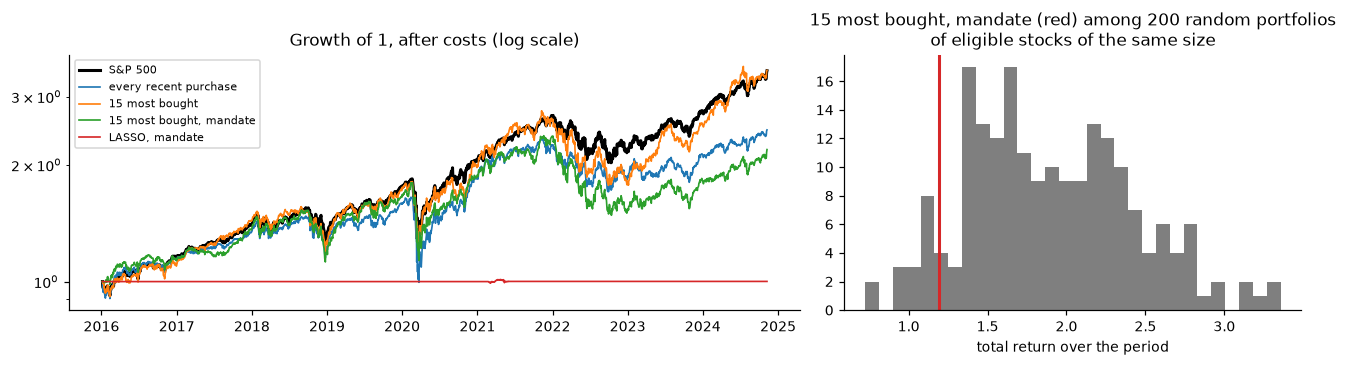

In [10]:
labels = {"copy_everything|unscreened": "every recent purchase", "copy_everything|screened": "every recent purchase, mandate",
          "most_bought|unscreened": "15 most bought", "most_bought|screened": "15 most bought, mandate",
          "past_winners|screened": "past winners, mandate", "lasso|screened": "LASSO, mandate", "omp|screened": "OMP, mandate",
          "ridge|screened": "ridge, mandate", "gbm|screened": "boosted trees, mandate"}
rows = []
for k, name in labels.items():
    v = res["portfolios"][k]
    rows.append({"rule": name, "return / year": pct(v["cagr"]), "alpha / year": pct(v["alpha_annual"]),
                 "alpha 95% interval": f"{pct(v['alpha_ci_low'])} to {pct(v['alpha_ci_high'])}", "beta": round(v["beta"], 2),
                 "invested": f"{100 * v['avg_exposure']:.0f}%", "turnover / year": round(v["annual_turnover"], 1),
                 "random portfolios doing at least as well": f"{100 * v['vs_random_same_size']['p_value']:.0f}%" if "vs_random_same_size" in v else ""})
print(f"S&P 500 over the same period: {pct(spy_cagr)} a year. Alpha: return not explained by the exposure to the S&P 500.")
display(pd.DataFrame(rows).set_index("rule"))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].plot(growth.index, growth["SPY"], color="black", lw=2, label="S&P 500")
for k in ["copy_everything|unscreened", "most_bought|unscreened", "most_bought|screened", "lasso|screened"]:
    ax[0].plot(growth.index, growth[k].ffill().fillna(1.0), lw=1.1, label=labels[k])     # a rule not yet invested stays at 1
ax[0].set_yscale("log"); ax[0].legend(fontsize=7); ax[0].set(title="Growth of 1, after costs (log scale)")
v = res["portfolios"]["most_bought|screened"]["vs_random_same_size"]
ax[1].hist(v["null_totals"], bins=30, color="tab:gray"); ax[1].axvline(v["strategy_total"], color="tab:red", lw=2)
ax[1].set(title="15 most bought, mandate (red) among 200 random portfolios\nof eligible stocks of the same size", xlabel="total return over the period")
plt.tight_layout(); plt.show()

**Reading.**
- Holding everything members buy loses about four points a year to the index at the same market exposure. The 15 most bought stocks do as well as the index, no better.
- Restricting to the mandate lowers the result of the same rules. That is a cost of the constraint in this period, not a failure of the filter.
- The LASSO portfolio is almost never invested: the model predicts nothing above zero, so it buys nothing. For a client this is the correct behaviour of a rule that has no information.
- No rule is in the top 5% of the random portfolios; most are in the lower half. One caution on this benchmark: its stocks are drawn among companies still listed today, which favours the random portfolios. It makes the test harder to pass; it does not change the comparison with the index.

### Is the result stable over time?

Following members of Congress became a popular idea around 2020–2023. If disclosures had started to carry information then, the recent years should look different from the early ones.

In [11]:
g = growth[["SPY", "most_bought|unscreened", "copy_everything|unscreened"]].ffill().pct_change().fillna(0.0)
yearly = (1 + g).groupby(g.index.year).prod() - 1
tab = pd.DataFrame({"purchases": {int(k): v["purchases"] for k, v in res["by_year"].items()},
                    "average purchase vs S&P 500 (63 days)": {int(k): pct(v["mean"], 2) for k, v in res["by_year"].items()},
                    "t": {int(k): round(v["t"], 1) for k, v in res["by_year"].items()}})
tab["15 most bought"] = yearly["most_bought|unscreened"].map(pct); tab["every recent purchase"] = yearly["copy_everything|unscreened"].map(pct)
tab["S&P 500"] = yearly["SPY"].map(pct)
display(tab)
for name, m in [("2016-2019", g.index.year <= 2019), ("2020 onwards", g.index.year >= 2020)]:
    z = g[m]; ann = (1 + z).prod() ** (252 / len(z)) - 1
    print(f"{name}: 15 most bought {pct(ann['most_bought|unscreened'])} a year, S&P 500 {pct(ann['SPY'])}")

,purchases,average purchase vs S&P 500 (63 days),t,15 most bought,every recent purchase,S&P 500
2016,1500,-0.46%,-1.5,+9.6%,+13.6%,+14.8%
2017,1796,+0.09%,0.3,+30.5%,+18.1%,+21.7%
2018,1884,-0.53%,-1.9,-10.8%,-8.4%,-4.6%
2019,2284,-0.77%,-2.8,+35.0%,+29.6%,+31.2%
2020,3310,+1.22%,3.9,+16.0%,+16.9%,+18.3%
2021,2194,-1.98%,-5.7,+30.1%,+21.0%,+28.7%
2022,1379,+1.02%,2.5,-30.2%,-17.0%,-18.2%
2023,1373,-1.22%,-3.0,+40.7%,+14.0%,+26.2%
2024,469,-1.52%,-2.0,+37.3%,+15.7%,+27.0%


2016-2019: 15 most bought +14.6% a year, S&P 500 +15.1%
2020 onwards: 15 most bought +15.8% a year, S&P 500 +15.3%


**Reading.** The sign of the average purchase changes from year to year and no recent period stands out. The 15 most bought stocks match the index in both halves. They beat it clearly in 2023 and 2024 and lost much more in 2022: these are mostly large technology stocks, which amplify the market in both directions. That is more risk, not information, and it is probably what made the idea look so good when it became popular.

## 7. Conclusion, limits, and what the locked period is for

**Conclusion for the client.** On ten years of disclosures from both chambers, buying after the disclosure does not beat the index, and no selection rule tested (sparse or not) improves on it. The convex-relaxation tools did their job: the LASSO returned an empty model where the signal-to-noise ratio does not allow recovery, and the detectability diagram explains why before any return is used. The recommendation is not to commit money to the rule, and to revisit only if the locked period contradicts the development period.

**Limits.**
1. **Missing filings.** Paper filings (about three in ten, more in the early years) are scans and were not read. Members who file on paper are absent.
2. **Amounts are ranges** (for example 1,001 to 15,000 dollars); position sizes are approximate.
3. **Prices.** Free sources. Delisted companies have prices from 2016 only, so rules are judged from 2016; about 1% of trades have no price at all. Impossible quotes were removed by rule (`clean_prices`).
4. **The random benchmark** draws among companies still listed today (see section 6).
5. **The mandate filter** is applied as given; companies whose accounts cannot be read are refused, which shrinks the eligible universe.
6. **One horizon** (63 days) and one family of rules were studied in depth; 21 and 126 days give the same sign for the average purchase.
7. **Multiple testing.** Fifteen portfolio variants were computed on the development period. This is why the final judgement belongs to the locked period.

**Locked period.** The last 24 months were excluded from every computation above. The final version of this report will run the frozen code once on them (`python scripts/run_research.py --final`) and report the result whatever it is.

## 8. Use of AI

*Draft to be completed and rewritten by the student. The factual log is in `docs/AI_USAGE_LOG.md`.*

**What the AI assistant (Claude) did.** It wrote most of the code of the repository (data collection, parsers, models, backtest, tests) and a first draft of this text, in a long working session that I directed. It proposed the overall design (walk-forward protocol, locked period, random-portfolio benchmark, detectability study).

**What it got wrong, and how it was found.** Each of these changed the numbers, which is why they are listed.
- The first parser of House filings assumed a layout that the real PDFs do not have: 9 of 20 real filings were read. Found by testing on the live site, corrected against real filings.
- The first full download stored four years (2014–2017) as "no stock", because the old form has no asset-type box, and lost about 5,500 tickers because of broken letter case in the PDFs. Found by profiling the result by year.
- The first random benchmark redrew stocks at every rebalancing and paid far more costs than the strategy, so every rule looked significant. Rewritten.
- The first evaluation of the models pooled all months and mixed ranking skill with time effects. Replaced by a month-by-month evaluation.
- The mandate filter read debt under a single accounting label; about a quarter of the stocks that passed did so with understated debt. Found by auditing well-known companies, corrected.
- The price source throttled the first download (half the tickers missing) and contained impossible quotes.

**What I did and checked myself.** *(to be written by the student: the choice of the question and of the constraints; which results were recomputed or checked by hand; what was understood and can be explained: the timing convention, why the member columns are orthogonal, the detection threshold, the PCP algorithm, the walk-forward protocol, the reading of each table.)*

**What I take from it.** *(to be written by the student.)*

## Appendix: reproduce

```bash
pip install -r requirements.txt
python scripts/build_dataset.py --stage ingest     # downloads the filings (about 2 hours, resumable)
python scripts/build_dataset.py --stage market     # prices, company accounts, mandate screen (needs free API keys, see README)
python scripts/detectability.py                    # section 3
python scripts/run_research.py --null 200          # sections 5 and 6, development period
pytest                                             # tests
```
The stored tables read by this notebook are produced by these commands; they are not part of the archive, as required.